# Making A L-Layer Deep Neural Network From Scratch(Including Comparison of Initializations and Optimizations)
---

Importing libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_moons, make_circles, make_classification, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, regularizers

np.random.seed(42)
tf.random.set_seed(42)
print("ready")

ready


Module 1: L Layer Deeep Neural Network

In [3]:
#complete modular functions
def sigmoid(Z):
    A = 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))
    cache = Z
    return A, cache

def sigmoid_backward(dA, cache):
    Z = cache
    s = 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))
    dZ = dA * s * (1.0 - s)
    return dZ

def relu(Z):
    A = np.maximum(0.0, Z)
    cache = Z
    return A, cache

def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0.0
    return dZ

def initialize_param(layer_dims):
    parameters = {}
    L = len(layer_dims)
    for l in range(1, L):
        parameters[f'W{l}'] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2 / layer_dims[l-1])
        parameters[f'b{l}'] = np.zeros((layer_dims[l], 1))
    return parameters

def linear_forward(A, W, b):
    Z = np.dot(W, A) + b
    cache = (A, W, b)
    return Z, cache

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    else:
        raise ValueError(f"Unsupported activation: {activation}")
    cache = (linear_cache, activation_cache)
    return A, cache

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2
    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters[f'W{l}'], parameters[f'b{l}'], "relu")
        caches.append(cache)

    AL, cache = linear_activation_forward(A, parameters[f'W{L}'], parameters[f'b{L}'], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y):
    m = Y.shape[1]
    eps = 1e-15
    AL = np.clip(AL, eps, 1.0 - eps)
    cost = - (1.0 / m) * np.sum(Y * np.log(AL) + (1.0 - Y) * np.log(1.0 - AL))
    return float(np.squeeze(cost))

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = (1.0 / m) * np.dot(dZ, A_prev.T)
    db = (1.0 / m) * np.sum(dZ, axis=1, keepdims=True)
    dA_prev = np.dot(W.T, dZ)
    return dA_prev, dW, db

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    else:
        raise ValueError(f"Unsupported activation: {activation}")

    dA_prev, dW, db = linear_backward(dZ, linear_cache)
    return dA_prev, dW, db

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    eps = 1e-15

    AL_safe = np.clip(AL, eps, 1.0 - eps)
    dAL = - (np.divide(Y, AL_safe) - np.divide(1.0 - Y, 1.0 - AL_safe))

    current_cache = caches[L - 1]
    grads[f'dA{L-1}'], grads[f'dW{L}'], grads[f'db{L}'] = linear_activation_backward(dAL, current_cache, "sigmoid")

    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads[f'dA{l+1}'], current_cache, "relu")
        grads[f'dA{l}'] = dA_prev_temp
        grads[f'dW{l+1}'] = dW_temp
        grads[f'db{l+1}'] = db_temp

    return grads

def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters[f'W{l}'] -= learning_rate * grads[f'dW{l}']
        parameters[f'b{l}'] -= learning_rate * grads[f'db{l}']
    return parameters

def predict(X, y, parameters):
    m = X.shape[1]
    p = np.zeros((1, m))
    probas, _ = L_model_forward(X, parameters)
    p[probas > 0.5] = 1.0
    acc = float(np.sum(p == y) / m)
    return p, acc

print("all functions ready")

all functions ready


In [4]:
def L_layer_model(X,Y, layer_dims, learning_rate=0.0075, num_iterations=3000, print_cost=False):
  np.random.seed(1)
  costs = []
  parameters = initialize_param(layer_dims)

  for i in range(num_iterations):
    AL,caches=L_model_forward(X,parameters)
    cost=compute_cost(AL,Y)
    grads=L_model_backward(AL,Y,caches)
    parameters=update_parameters(parameters,grads,learning_rate)

    if print_cost and (i% 500 ==0 or i == num_iterations -1):
      print(f"cost after iteration {i:5d}: {cost:6f}")
    if i% 100 == 0:
      costs.append(cost)
  return parameters, costs

def plot_decision_boundary(predict_fn, X, y, title="Decision Boundary"):
  xmin,xmax = X[0,:].min() - 0.5, X[0,:].max() + 0.5
  ymin,ymax = X[1,:].min() - 0.5, X[1,:].max() + 0.5
  h= 0.02
  xx,yy =np.meshgrid(np.arange(xmin,xmax,h),np.arange(ymin,ymax,h))
  grid_points= np.c_[xx.ravel(), yy.ravel()].T
  Z,_= predict_fn(grid_points)
  Z= Z.reshape(xx.shape)

  plt.contour(xx,yy,Z, cmap=plt.cm.Spectral,alpha=0.6)
  plt.scatter(X[0,:],X[1,:],c=y.ravel(),s=30,cmap=plt.cm.Spectral,edgecolors="k")
  plt.xlabel("x1")
  plt.ylabel("x2")
  plt.title(title,fontsize=12,fontweight="bold")

X_data,y_data= make_moons(n_samples=1000, noise=0.25, random_state=42)
X_train_ml,X_test_ml,ytrain_ml,ytest_ml= train_test_split(X_data,y_data,test_size=0.25,random_state=42)

X_train_ml=X_train_ml.T
ytrain_ml =ytrain_ml.reshape(1,-1)
X_test_ml=X_test_ml.T
ytest_ml =ytest_ml.reshape(1,-1)

print(f"Training dataset shape: X= {X_train_ml.shape}, Y= {ytrain_ml.shape}")
print(f"Testing dataset shape: X= {X_test_ml.shape}, Y= {ytest_ml.shape}")


Training dataset shape: X= (2, 750), Y= (1, 750)
Testing dataset shape: X= (2, 250), Y= (1, 250)


Training a 4 layer Deep NN
cost after iteration     0: 0.646613
cost after iteration   500: 0.277577
cost after iteration  1000: 0.233608
cost after iteration  1500: 0.179494
cost after iteration  2000: 0.147365
cost after iteration  2499: 0.137108

Final Training Accuracy: 94.80%
Final Test Accuracy:     96.40%


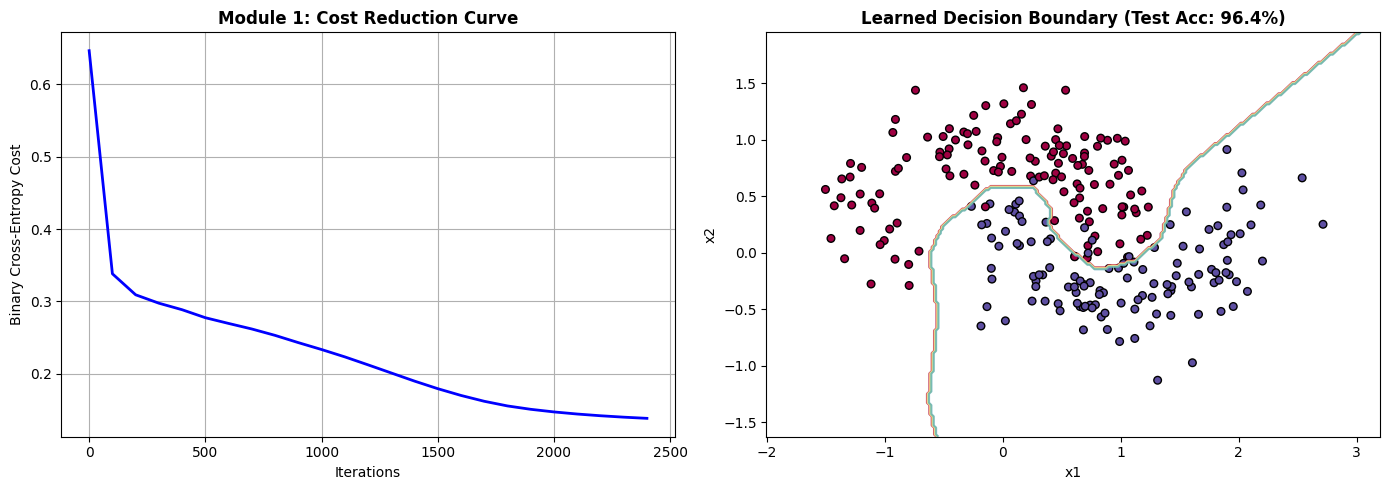

<Figure size 640x480 with 0 Axes>

In [5]:
layer_dims_ml = [2, 32, 16, 8, 1]
print("Training a 4 layer Deep NN")

params_ml, costs_ml = L_layer_model(X_train_ml, ytrain_ml, layer_dims_ml, learning_rate=0.03, num_iterations=2500, print_cost=True)

_, train_acc_ml = predict(X_train_ml, ytrain_ml, params_ml)
_, test_acc_ml = predict(X_test_ml, ytest_ml, params_ml)
print(f"\nFinal Training Accuracy: {train_acc_ml*100:.2f}%")
print(f"Final Test Accuracy:     {test_acc_ml*100:.2f}%")

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(np.arange(len(costs_ml)) * 100, costs_ml, 'b-', lw=2)
plt.xlabel('Iterations')
plt.ylabel('Binary Cross-Entropy Cost')
plt.title('Module 1: Cost Reduction Curve', fontweight='bold')
plt.grid(True)

plt.subplot(1, 2, 2)
plot_decision_boundary(lambda x: predict(x, np.zeros((1, x.shape[1])), params_ml), X_test_ml, ytest_ml,
                       f"Learned Decision Boundary (Test Acc: {test_acc_ml*100:.1f}%)")
plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()

Module 2: Initialization, Regularization, Gradient Checking and Optimization

In [14]:
#different types of inits

def initialize_params_zeros(layer_dims):
  parameters={}
  for l in range(1,len(layer_dims)):
    parameters[f'W{l}'] = np.zeros((layer_dims[l],layer_dims[l-1]))
    parameters[f'b{l}'] = np.zeros((layer_dims[l],1))
  return parameters

def initialize_params_random(layer_dims, scale=10.0):
  parameters={}
  for l in range(1,len(layer_dims)):
    parameters[f'W{l}'] = np.random.randn(layer_dims[l],layer_dims[l-1])* scale
    parameters[f'b{l}'] = np.zeros((layer_dims[l],1))
  return parameters

def initialize_params_he(layer_dims):
  parameters={}
  for l in range(1,len(layer_dims)):
    parameters[f'W{l}'] = np.random.randn(layer_dims[l],layer_dims[l-1])* np.sqrt(2.0/layer_dims[l-1])
    parameters[f'b{l}'] = np.zeros((layer_dims[l],1))
  return parameters



In [7]:
#l2 regularization and dropout
def compute_cost_l2(AL,Y,parameters, lambd):
  #In this function we do binary cross entropy + L2 frobenius norm pernalty
  m=Y.shape[1]
  cross_entropy_cost= compute_cost(AL,Y)
  L=len(parameters)//2
  l2_sum = sum(np.sum(np.square(parameters[f'W{l}'])) for l in range(1,L+1))
  l2_cost= (lambd/(2.0*m))*l2_sum
  return cross_entropy_cost + l2_cost

def backward_prop_with_l2(AL,Y,caches,parameters,lambd):
  #this function computes the l2 weight decay penalty added to dW
  grads= L_model_backward(AL,Y,caches)
  m=Y.shape[1]
  L=len(parameters)//2
  for l in range(1,L+2):
    grads[f'dW{l}'] +=(lambd/m) * parameters[f'W{l}']
  return grads

def forward_prop_with_dropout(X,parameters,keep_prob=0.8):
  #forward prop with inverted dropout on hidden layers
  caches=[]
  A=X
  L=len(parameters)//2
  for l in range(1,L):
    A_prev= A
    A,linear_act_cache = linear_activation_forward(A_prev, parameters[f'W{l}'], parameters[f'b{l}'], "relu")
    D = np.random.rand(*A.shape) < keep_prob
    A = (A*D)/ keep_prob
    cache = (linear_act_cache,D)
    caches.append(cache)
  AL, linear_act_cache = linear_activation_forward(A, parameters[f'W{L}'], parameters[f'b{L}'], "sigmoid")
  caches.append((linear_act_cache, None))
  return AL, caches

def backward_prop_with_dropout(AL,Y, caches, keep_prob=0.8):
  #backward through the dropout masks
  grads={}
  L=len(caches)
  m=AL.shape[1]
  Y=Y.reshape(AL.shape)
  eps= 1e-15
  AL_safe= np.clip(AL,eps, 1.0-eps)
  dAL=(np.divide(Y,AL_safe)-np.divide(1.0-Y,1.0-AL_safe))

  current_cache,_=caches[L-1]
  grads[f'dA{L-1}'], grads[f'dW{L}'], grads[f'db{L}'] = linear_activation_backward(dAL, current_cache, "sigmoid")
  for l in reversed(range(L - 1)):
        current_cache, D = caches[l]
        #dropout mask application
        dA_curr = (grads[f'dA{l+1}'] * D) / keep_prob
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dA_curr, current_cache, "relu")
        grads[f'dA{l}'] = dA_prev_temp
        grads[f'dW{l+1}'] = dW_temp
        grads[f'db{l+1}'] = db_temp

  return grads

In [15]:
def train_init_experiment(init_type, layers_dims, X, Y, epochs=1500, lr=0.03):
    if init_type == "zeros":
        params = initialize_params_zeros(layers_dims)
    elif init_type == "random":
        params = initialize_params_random(layers_dims, scale=10.0)
    elif init_type == "he":
        params = initialize_params_he(layers_dims)

    costs = []
    for i in range(epochs):
        AL, caches = L_model_forward(X, params)
        c = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches)
        params = update_parameters(params, grads, lr)
        if i % 50 == 0:
            costs.append(c)
    _, acc = predict(X, Y, params)
    return costs, acc, params

init_dims = [2, 16, 8, 1]
c_zeros, acc_zeros, _ = train_init_experiment("zeros", init_dims, X_train_ml, ytrain_ml)
c_rand, acc_rand, _ = train_init_experiment("random", init_dims, X_train_ml, ytrain_ml)
c_he, acc_he, _ = train_init_experiment("he", init_dims, X_train_ml, ytrain_ml)


--- Initialization Comparison Results ---
Zeros Initialization Final Acc:  50.5% (Symmetry locked at random guessing)
Random Large Init Final Acc:    50.5% (Suboptimal / Saturation)
He Initialization Final Acc:      88.5% (Optimal Variance Preservation)


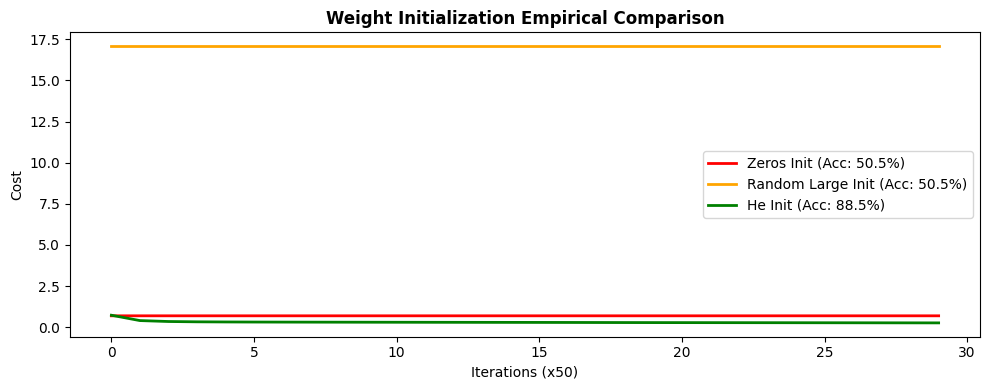

In [16]:

print(f"\n--- Initialization Comparison Results ---")
print(f"Zeros Initialization Final Acc:  {acc_zeros*100:.1f}% (Symmetry locked at random guessing)")
print(f"Random Large Init Final Acc:    {acc_rand*100:.1f}% (Suboptimal / Saturation)")
print(f"He Initialization Final Acc:      {acc_he*100:.1f}% (Optimal Variance Preservation)")

plt.figure(figsize=(10, 4))
plt.plot(c_zeros, label=f'Zeros Init (Acc: {acc_zeros*100:.1f}%)', color='red', lw=2)
plt.plot(c_rand, label=f'Random Large Init (Acc: {acc_rand*100:.1f}%)', color='orange', lw=2)
plt.plot(c_he, label=f'He Init (Acc: {acc_he*100:.1f}%)', color='green', lw=2)
plt.xlabel('Iterations (x50)')
plt.ylabel('Cost')
plt.title('Weight Initialization Empirical Comparison', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
from numpy.random import permutation
#optimization functions

def random_mini_batches( X, Y, mini_batch_size=64, seed=0):
  np.random.seed(seed)
  m=X.shape[1]
  mini_batches =[]

  permutations = list(np.random.permutation(m))
  shuffled_X= X[:, permutations]
  shuffled_Y= Y[:, permutations].reshape((1,m))

  num_complete_minibatches = math.floor(m/ mini_batch_size)
  for k in range(num_complete_minibatches):
    mini_batch_X = shuffled_X[:, k * mini_batch_size : (k + 1) * mini_batch_size]
    mini_batch_Y = shuffled_Y[:, k * mini_batch_size : (k + 1) * mini_batch_size]
    mini_batches.append((mini_batch_X, mini_batch_Y))

  if m % mini_batch_size != 0:
    mini_batch_X = shuffled_X[:, num_complete_minibatches * mini_batch_size :]
    mini_batch_Y = shuffled_Y[:, num_complete_minibatches * mini_batch_size :]
    mini_batches.append((mini_batch_X, mini_batch_Y))
  return mini_batches

#optimizers state inits
def initialize_velocity(parameters):
  v = {}
  for l in range(1, len(parameters) // 2 + 1):
    v[f'dW{l}'] = np.zeros_like(parameters[f'W{l}'])
    v[f'db{l}'] = np.zeros_like(parameters[f'b{l}'])
  return v

def initialize_rmsprop(parameters):
  s = {}
  for l in range(1, len(parameters) // 2 + 1):
      s[f'dW{l}'] = np.zeros_like(parameters[f'W{l}'])
      s[f'db{l}'] = np.zeros_like(parameters[f'b{l}'])
  return s

def initialize_adam(parameters):
  v = initialize_velocity(parameters)
  s = initialize_rmsprop(parameters)
  return v, s


Benchmarking Optimizers across 100 Epochs...
Optimizer    | Final Cost | Train Acc  | Time (s)
--------------------------------------------------
MiniBatch SGD | 0.2783     | 87.3     % | 0.38    
Momentum     | 0.2786     | 87.6     % | 0.39    
RMSprop      | 0.1255     | 94.8     % | 0.45    
Adam         | 0.1261     | 94.7     % | 0.53    


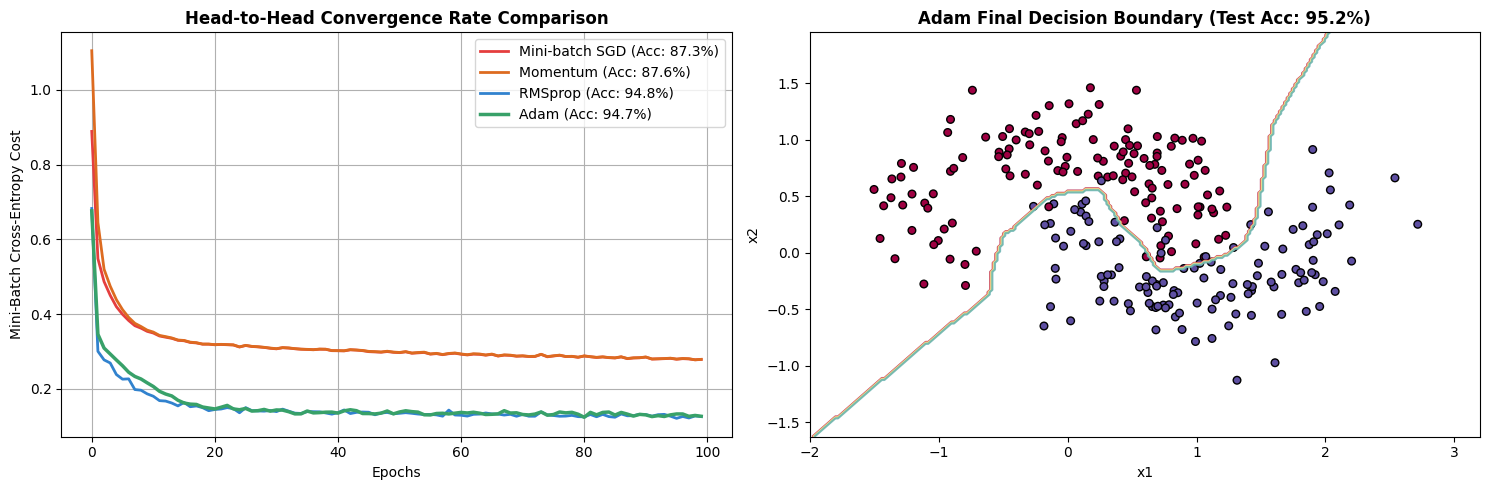

In [24]:

# Optimizer update steps
def update_parameters_with_sgd(parameters, grads, learning_rate):
    for l in range(1, len(parameters) // 2 + 1):
        parameters[f'W{l}'] -= learning_rate * grads[f'dW{l}']
        parameters[f'b{l}'] -= learning_rate * grads[f'db{l}']
    return parameters

def update_parameters_with_momentum(parameters, grads, v, beta1, learning_rate):
    for l in range(1, len(parameters) // 2 + 1):
        v[f'dW{l}'] = beta1 * v[f'dW{l}'] + (1.0 - beta1) * grads[f'dW{l}']
        v[f'db{l}'] = beta1 * v[f'db{l}'] + (1.0 - beta1) * grads[f'db{l}']
        parameters[f'W{l}'] -= learning_rate * v[f'dW{l}']
        parameters[f'b{l}'] -= learning_rate * v[f'db{l}']
    return parameters, v

def update_parameters_with_rmsprop(parameters, grads, s, beta2, learning_rate, epsilon=1e-8):
    for l in range(1, len(parameters) // 2 + 1):
        s[f'dW{l}'] = beta2 * s[f'dW{l}'] + (1.0 - beta2) * np.square(grads[f'dW{l}'])
        s[f'db{l}'] = beta2 * s[f'db{l}'] + (1.0 - beta2) * np.square(grads[f'db{l}'])
        parameters[f'W{l}'] -= learning_rate * (grads[f'dW{l}'] / (np.sqrt(s[f'dW{l}']) + epsilon))
        parameters[f'b{l}'] -= learning_rate * (grads[f'db{l}'] / (np.sqrt(s[f'db{l}']) + epsilon))
    return parameters, s

def update_parameters_with_adam(parameters, grads, v, s, t, learning_rate=0.001,
                                beta1=0.9, beta2=0.999, epsilon=1e-8):
    v_corrected = {}
    s_corrected = {}
    for l in range(1, len(parameters) // 2 + 1):
        # Moving averages of gradients
        v[f'dW{l}'] = beta1 * v[f'dW{l}'] + (1.0 - beta1) * grads[f'dW{l}']
        v[f'db{l}'] = beta1 * v[f'db{l}'] + (1.0 - beta1) * grads[f'db{l}']
        v_corrected[f'dW{l}'] = v[f'dW{l}'] / (1.0 - beta1 ** t)
        v_corrected[f'db{l}'] = v[f'db{l}'] / (1.0 - beta1 ** t)

        # Moving averages of squared gradients
        s[f'dW{l}'] = beta2 * s[f'dW{l}'] + (1.0 - beta2) * np.square(grads[f'dW{l}'])
        s[f'db{l}'] = beta2 * s[f'db{l}'] + (1.0 - beta2) * np.square(grads[f'db{l}'])
        s_corrected[f'dW{l}'] = s[f'dW{l}'] / (1.0 - beta2 ** t)
        s_corrected[f'db{l}'] = s[f'db{l}'] / (1.0 - beta2 ** t)

        # Parameter update with adaptive scaling
        parameters[f'W{l}'] -= learning_rate * (v_corrected[f'dW{l}'] / (np.sqrt(s_corrected[f'dW{l}']) + epsilon))
        parameters[f'b{l}'] -= learning_rate * (v_corrected[f'db{l}'] / (np.sqrt(s_corrected[f'db{l}']) + epsilon))

    return parameters, v, s

# Unified Model Optimizer Benchmark Harness
def run_optimizer_benchmark(X, Y, layers_dims, optimizer="adam", learning_rate=0.005,
                            mini_batch_size=64, num_epochs=100, beta1=0.9, beta2=0.999):
    np.random.seed(42)
    parameters = initialize_params_he(layers_dims)
    costs = []
    t = 0
    seed = 10

    if optimizer == "momentum":
        v = initialize_velocity(parameters)
    elif optimizer == "rmsprop":
        s = initialize_rmsprop(parameters)
    elif optimizer == "adam":
        v, s = initialize_adam(parameters)

    start_time = time.time()
    for i in range(num_epochs):
        seed += 1
        minibatches = random_mini_batches(X, Y, mini_batch_size, seed)
        cost_total = 0

        for minibatch_X, minibatch_Y in minibatches:
            AL, caches = L_model_forward(minibatch_X, parameters)
            cost_total += compute_cost(AL, minibatch_Y)
            grads = L_model_backward(AL, minibatch_Y, caches)

            if optimizer == "sgd":
                parameters = update_parameters_with_sgd(parameters, grads, learning_rate)
            elif optimizer == "momentum":
                parameters, v = update_parameters_with_momentum(parameters, grads, v, beta1, learning_rate)
            elif optimizer == "rmsprop":
                parameters, s = update_parameters_with_rmsprop(parameters, grads, s, beta2, learning_rate)
            elif optimizer == "adam":
                t += 1
                parameters, v, s = update_parameters_with_adam(parameters, grads, v, s, t, learning_rate, beta1, beta2)

        costs.append(cost_total / len(minibatches))

    elapsed = time.time() - start_time
    _, acc = predict(X, Y, parameters)
    return costs, acc, elapsed, parameters

# Execute Head-to-Head Comparison on Noisy Classification Data
opt_dims = [2, 32, 16, 8, 1]
print("Benchmarking Optimizers across 100 Epochs...")
c_sgd, acc_sgd, t_sgd, p_sgd = run_optimizer_benchmark(X_train_ml, ytrain_ml, opt_dims, optimizer="sgd", learning_rate=0.01)
c_mom, acc_mom, t_mom, p_mom = run_optimizer_benchmark(X_train_ml, ytrain_ml, opt_dims, optimizer="momentum", learning_rate=0.01)
c_rms, acc_rms, t_rms, p_rms = run_optimizer_benchmark(X_train_ml, ytrain_ml, opt_dims, optimizer="rmsprop", learning_rate=0.005)
c_adm, acc_adm, t_adm, p_adm = run_optimizer_benchmark(X_train_ml, ytrain_ml, opt_dims, optimizer="adam", learning_rate=0.005)

print(f"{'Optimizer':<12} | {'Final Cost':<10} | {'Train Acc':<10} | {'Time (s)':<8}")
print("-" * 50)
print(f"{'MiniBatch SGD':<12} | {c_sgd[-1]:<10.4f} | {acc_sgd*100:<9.1f}% | {t_sgd:<8.2f}")
print(f"{'Momentum':<12} | {c_mom[-1]:<10.4f} | {acc_mom*100:<9.1f}% | {t_mom:<8.2f}")
print(f"{'RMSprop':<12} | {c_rms[-1]:<10.4f} | {acc_rms*100:<9.1f}% | {t_rms:<8.2f}")
print(f"{'Adam':<12} | {c_adm[-1]:<10.4f} | {acc_adm*100:<9.1f}% | {t_adm:<8.2f}")

# Plot Comparative Convergence Curves & Decision Surfaces
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(c_sgd, label=f'Mini-batch SGD (Acc: {acc_sgd*100:.1f}%)', color='#E53E3E', lw=2)
plt.plot(c_mom, label=f'Momentum (Acc: {acc_mom*100:.1f}%)', color='#DD6B20', lw=2)
plt.plot(c_rms, label=f'RMSprop (Acc: {acc_rms*100:.1f}%)', color='#3182CE', lw=2)
plt.plot(c_adm, label=f'Adam (Acc: {acc_adm*100:.1f}%)', color='#38A169', lw=2.5)
plt.xlabel('Epochs')
plt.ylabel('Mini-Batch Cross-Entropy Cost')
plt.title('Head-to-Head Convergence Rate Comparison', fontweight='bold')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plot_decision_boundary(lambda x: predict(x, np.zeros((1, x.shape[1])), p_adm), X_test_ml, ytest_ml,
                       f"Adam Final Decision Boundary (Test Acc: {predict(X_test_ml, ytest_ml, p_adm)[1]*100:.1f}%)")
plt.tight_layout()
plt.show()
